# Assignment 3 - Application of Clustering

In this assignment, we are tasked with predicting whether a given transaction is fraudulent or not. We are given a dataset on pre-processed credit card transactions and we have to train a Logistic Regression model on it for the same. The catch here is, the dataset, similar to the real world, is highly imbalanced i.e. the number of fraud transactions are very few in the same. We must figure out on how to build a model which can catch this problem despite this issue.

## Imports

Only for Colab

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !cp /content/drive/MyDrive/kaggle.json /content/kaggle.json
# !mkdir -p /root/.config/kaggle
# !cp kaggle.json /root/.config/kaggle
# !chmod 600 /root/.config/kaggle/kaggle.json

In [16]:
import numpy as np
import pandas as pd
import json

import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import kaggle
from kagglehub import KaggleDatasetAdapter

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.cluster import *
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

import imblearn
from imblearn.over_sampling import *
from imblearn.under_sampling import *
from imblearn.metrics import *
from imblearn.pipeline import make_pipeline

## Data Exploration

Going through the Kaggle Data Information page, we note the following:
1. The dataset is already processed into numeric values to hide sensitive information (hence no need for encoding).
2. PCA has already been performed and we are given some of its principal components.
3. Two additional features are provided -
a. Time: Time elapsed in seconds since the first transaction
b. Amount: Monetary amount
4. Class contains the binary target labels

Also, as the dataset size is too big, you would have to download from the Kaggle website with your API key

In [4]:
kaggle.api.dataset_download_files('mlg-ulb/creditcardfraud', path='./data', unzip=True)

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


In [5]:
data = pd.read_csv('data/creditcard.csv')  # load the dataset

In [6]:
data    # display some of its rows

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [7]:
data.describe()  # some statistics on it

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


To see the class imbalance:

In [8]:
neg_class = data[data['Class'] == 0]
pos_class = data[data['Class'] == 1]
neg_class_count, pos_class_count = data['Class'].value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(data) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(data) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")

Percentage of Positive Class data points: 0.1727485630620034
Percentage of Negative Class data points: 99.82725143693798
Ratio of number of Negative Class to that of Positive Class : 577.8760162601626


In [9]:
x, y = data.drop(columns=['Class']), data['Class']

#### Why is this bad?
1. Most of classifiers (like Logistic Regression) is built on the assumption that the dataset is balanced.
2. Standard classification algorithms often perform poorly on such datasets, as they tend to classify most instances as the majority class to achieve high overall accuracy, ignoring the minority class.
3. The usual metrics used for gauging a model's performance, such as Accuracy, Precision, AUC-ROC and F1, are highly senstitive to the class imbalance and may indicate misleading results.

#### What can be done?
We have three options in hand. We can choose either one or more:
1. Process the Dataset
2. Use better models (which is out of scope for our problem statement)
3. Use better metrics

## Pipeline

In [142]:
def report_generator(y_pred, y_test, name):
    report = classification_report_imbalanced(y_test, y_pred,
    labels=[0, 1], target_names=['Not Fraud', 'Fraud'], output_dict=True)
    d = {
        "pre": "Precison", "rec": "Recall",
        "spe": "Specificity", "f1": "F1 Score",
        "geo": "FM Index", "iba": "IBA",
        "sup": "Support", "avg_pre": "Average Precision",
        "avg_rec": "Average Recall", "avg_spe": "Average Specificity",
        "avg_f1": "Average F1 Score", "avg_geo": "Average FM Index",
        "avg_iba": "Average IBA", "total_support": "Total Support"
    }
    better_report = {
        "Fraud": dict(), "Not Fraud": dict(), 
        "Average Precision": 0,"Average Recall": 0,
        "Average Specificity": 0,
        "Average F1 Score": 0,
        "Average FM Index": 0,
        "Average Index Balanced Accuracy": 0,
        "Total Support": 0
    }
    for i in report:
        if i == "Fraud":
            k = report[i]
            for j in k:
                better_report["Fraud"][d[j]] = k[j]
        elif i == "Not Fraud":
            k = report[i]
            for j in k:
                better_report["Not Fraud"][d[j]] = k[j]
        else:
            better_report[d[i]] = report[i]
    fraud, not_fraud = better_report['Fraud'], better_report['Not Fraud']

    fig, axs = plt.subplots(4, 2, figsize= (10, 10), constrained_layout = True)
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        x = ["Fraud", "Not Fraud"]
        if i != 'Support':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y)
            axs[k, l].set_ylabel(f"Log of {i} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    axs[k, l].bar(x=["Fraud", "Not Fraud"], height=[np.log(len(pos_class)), np.log(len(neg_class))])
    axs[k, l].set_title("Sample Size Comparison")
    axs[k, l].set_xlabel(f"Class")
    axs[k, l].set_ylabel(f"Log of Size Value")
    for q in range(len(x)):
        axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report.png")
    plt.show()

In [143]:
def plot_resampling(X, y, sampler, ax, title=None):
    X_res, y_res = sampler.fit_resample(X, y)
    ax.scatter(X_res[:, 0], X_res[:, 1], c=y_res, alpha=0.8, edgecolor="k")
    if title is None:
        title = f"Resampling with {sampler.__class__.__name__}"
    ax.set_title(title)
    sns.despine(ax=ax, offset=10)

In [144]:
# TODO: Fix this
def plot_decision_function(X, y, clf, ax, title=None):
    plot_step = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, plot_step), np.arange(y_min, y_max, plot_step)
    )

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.4)
    ax.scatter(X[:, 0], X[:, 1], alpha=0.8, c=y, edgecolor="k")
    if title is not None:
        ax.set_title(title)

In [145]:
def pipeline(data, name, sampler = None):
    x, y = data.drop(columns=['Class'])[['V1', 'V2']].to_numpy(), data['Class'].to_numpy()
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25)
    
    clf = LogisticRegression(solver="lbfgs")
    model = make_pipeline(sampler, clf).fit(X_train, y_train) if sampler else clf.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    report_generator(y_pred, y_test, name)
    
    return model

In [146]:
classifiers = []
samplers = []

In [ ]:
def show_decision_functions(data):
    clfs = classifiers
    data2 = data.sample(n=100000, axis=0)
    fig, axs = plt.subplots(nrows=len(clfs) // 2, ncols=2, figsize=(30, 15))
    print(axs)
    i, j = 0, 0

    for k in range(len(clfs)):
        cur_X, cur_Y = data2.drop(columns=['Class'])[['V1', 'V2']].to_numpy(), data2['Class'].to_numpy()
        cur_clf, cur_sampler = clfs[k], samplers[k]

        if len(axs) > 2:
            plot_decision_function(cur_X, cur_Y, cur_clf, axs[i, j], title=f"Using {cur_sampler}")
        else:
            plot_decision_function(cur_X, cur_Y, cur_clf, axs[j], title=f"Using {cur_sampler}")

        j += 1
        if j == 2:
            j = 0
            i += 1
    
    fig.suptitle(f"Decision function of Logistic Regression")
    fig.tight_layout()

## Straight Classification

What if we decide to classify directly without taking in account the class imbalance?

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


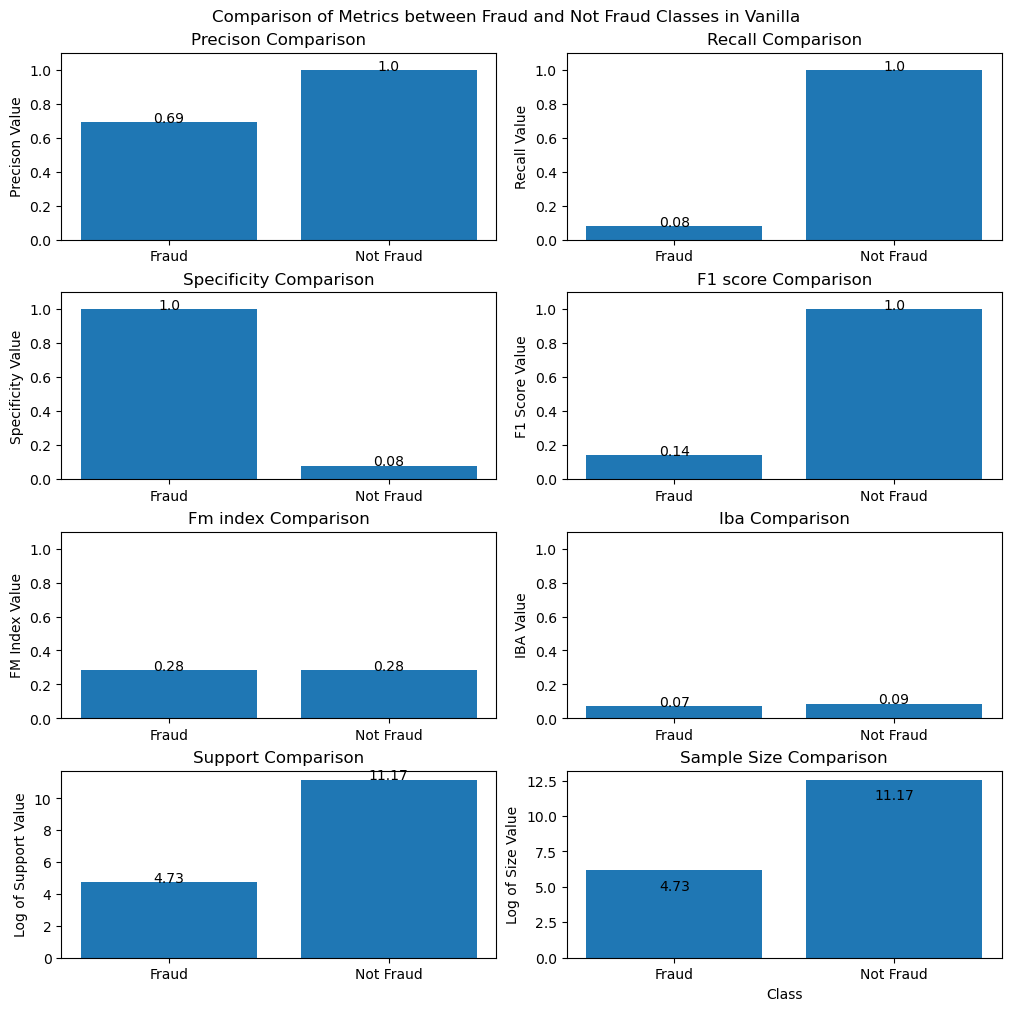

In [148]:
samplers.append("No Sampler")
classifiers.append(pipeline(data, name="Vanilla"))

Observations:
1. 

## Process the Dataset

The Dataset needs to be transformed (or more appropriately, resampled) to represent a better class distribution. Resampling means we can either <b>under-sample</b> from the majority class or <b>over-sample</b> from the minority class

### Over-sampling

We can add more examples from the minority class in the dataset to improve its percentage. There are different ways of doing the same:

#### Random Over-sampling

Randomly duplicate the records in the minority class.<br>
Pro:    Simple
Con:    Highlight specific datapoints in the class rather than generalize

In [149]:
new_pos_class = pos_class.sample(n=neg_class_count, replace=True)  # sampled to meet the size of negative class
data2 = pd.concat([new_pos_class, neg_class])

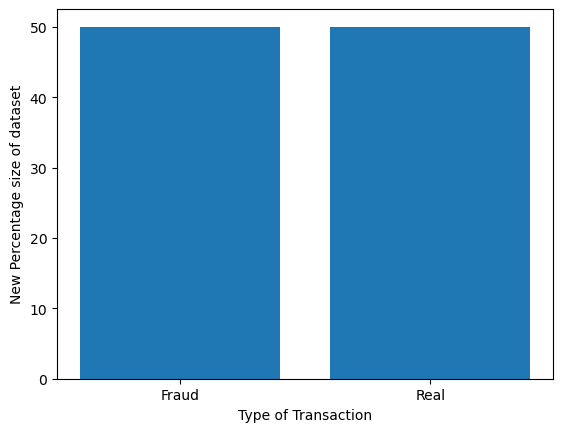

In [150]:
plt.bar(x=['Fraud', 'Real'], height=[len(new_pos_class) / len(data2) * 100, neg_class_count  / len(data2) * 100])
plt.xlabel("Type of Transaction")
plt.ylabel("New Percentage size of dataset")
plt.show()

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


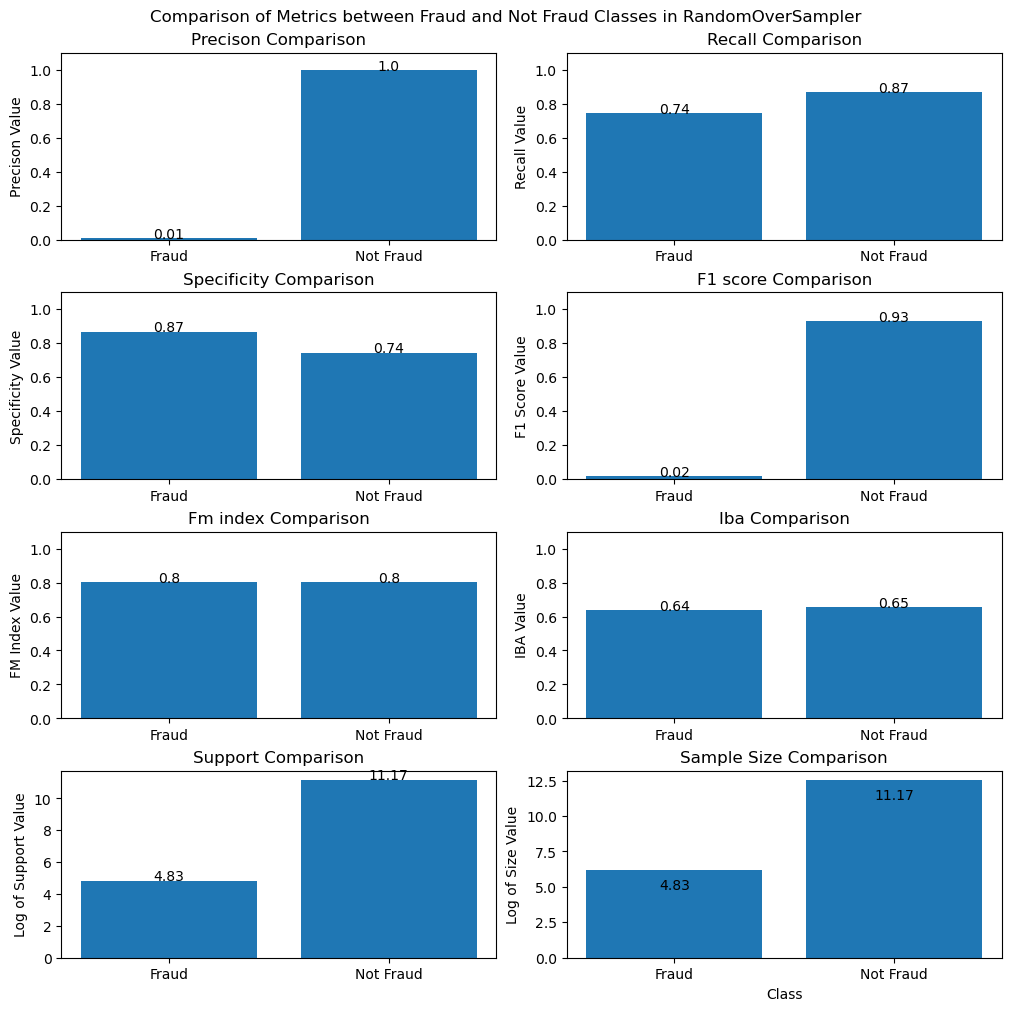

In [151]:
ros = RandomOverSampler(random_state=42)
ros.set_params(shrinkage=None)
samplers.append("RandomOverSampler(shrinkage = None)")
classifiers.append(pipeline(data, name="RandomOverSampler", sampler=ros))

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


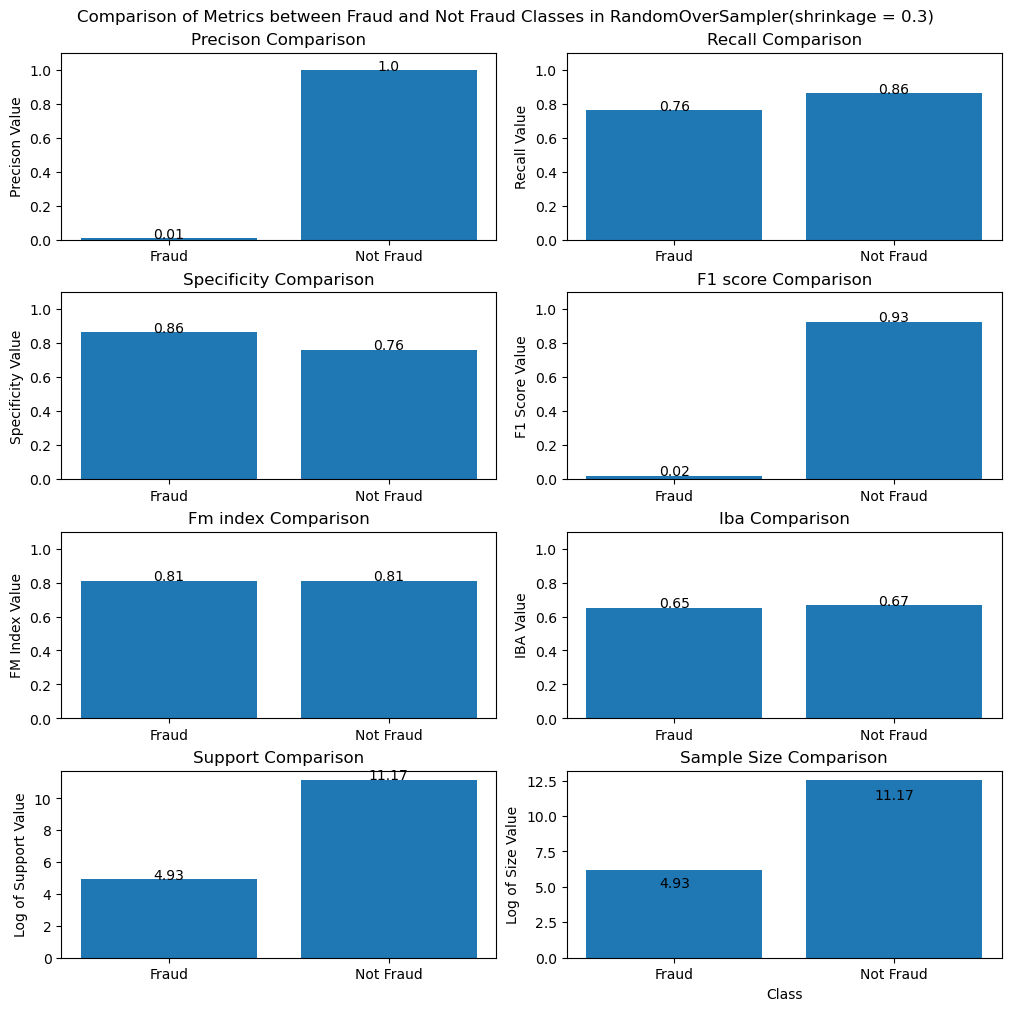

In [152]:
ros = RandomOverSampler(random_state=42)
ros.set_params(shrinkage=0.3)
samplers.append("RandomOverSampler(shrinkage = 0.3)")
classifiers.append(pipeline(data, name="RandomOverSampler(shrinkage = 0.3)", sampler=ros))

#### Synthetic Minority Oversampling Technique (SMOTE)

In this method, we add synthetic data points in the minority class keeping the features of the data roughly maintained. We do so by using the k-nearest neighbors method.

SMOTE algorithm works in 4 simple steps:
```
    1. Choose a minority class as the input vector.
    2. Find its k nearest neighbors (k_neighbors is specified as an argument in the SMOTE() function).
    3. Choose one of these neighbors and place a synthetic point anywhere on the line joining the point under consideration and its chosen neighbor.
    4. Repeat the steps until the data is balanced.
```

The minority class is over-sampled by taking each minority class sample and introducing synthetic examples along the line segments joining any/all of the k minority class nearest neighbors. Depending upon the amount of over-sampling required, neighbors from the k nearest neighbors are randomly chosen. Default implementation currently uses five nearest neighbors. For instance, if the amount of over-sampling needed is 200%, only two neighbors from the five nearest neighbors are chosen and one sample is generated in the direction of each.

Synthetic samples are generated in the following way: Take the difference between the feature vector (sample) under consideration and its nearest neighbor. Multiply this difference by a random number between 0 and 1, and add it to the feature vector under consideration. This causes the selection of a random point along the line segment between two specific features. This approach effectively forces the decision region of the minority class to become more general.

In [153]:
# Calculate the amount of over-sampling required:
print(f"Amount of Oversampling required for the Positive Class:{neg_class_count / pos_class_count}")

Amount of Oversampling required for the Positive Class:577.8760162601626


We need more than five nearest neighbors to actually perform the job.

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


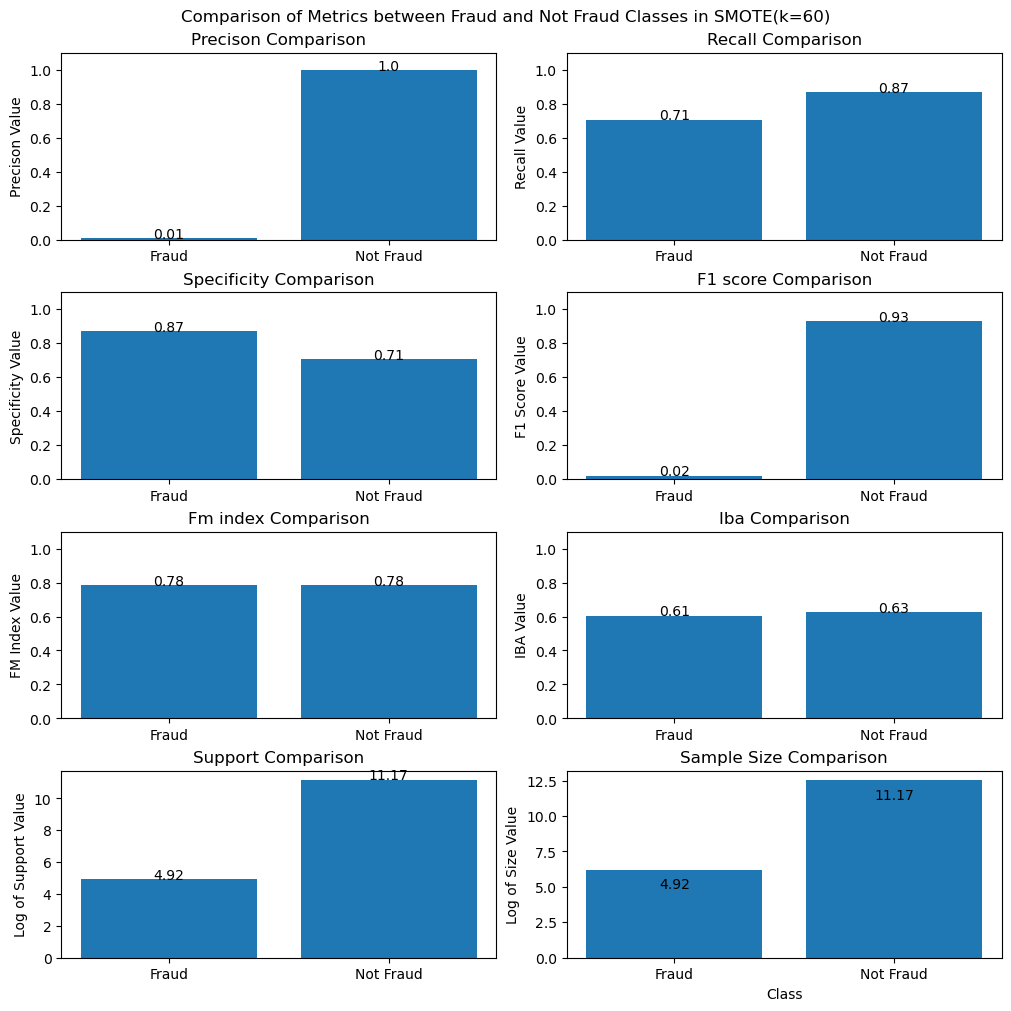

In [154]:
smote = SMOTE(k_neighbors=60)  # TODO: try changing k_neighbors and see what happens
samplers.append("SMOTE(k=60)")
classifiers.append(pipeline(data, name="SMOTE(k=60)", sampler=smote))

Visualize the process:

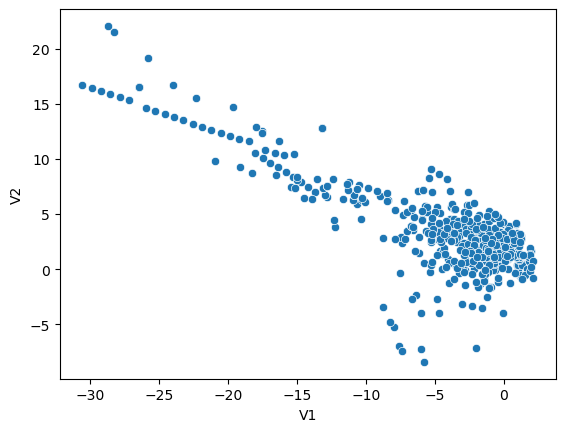

In [155]:
neg_2 = neg_class[['V1', 'V2', 'Class']]
pos_2 = pos_class[['V1', 'V2', 'Class']]

sns.scatterplot(x=pos_2['V1'], y=pos_2['V2'])
plt.show()

#### ADASYN

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


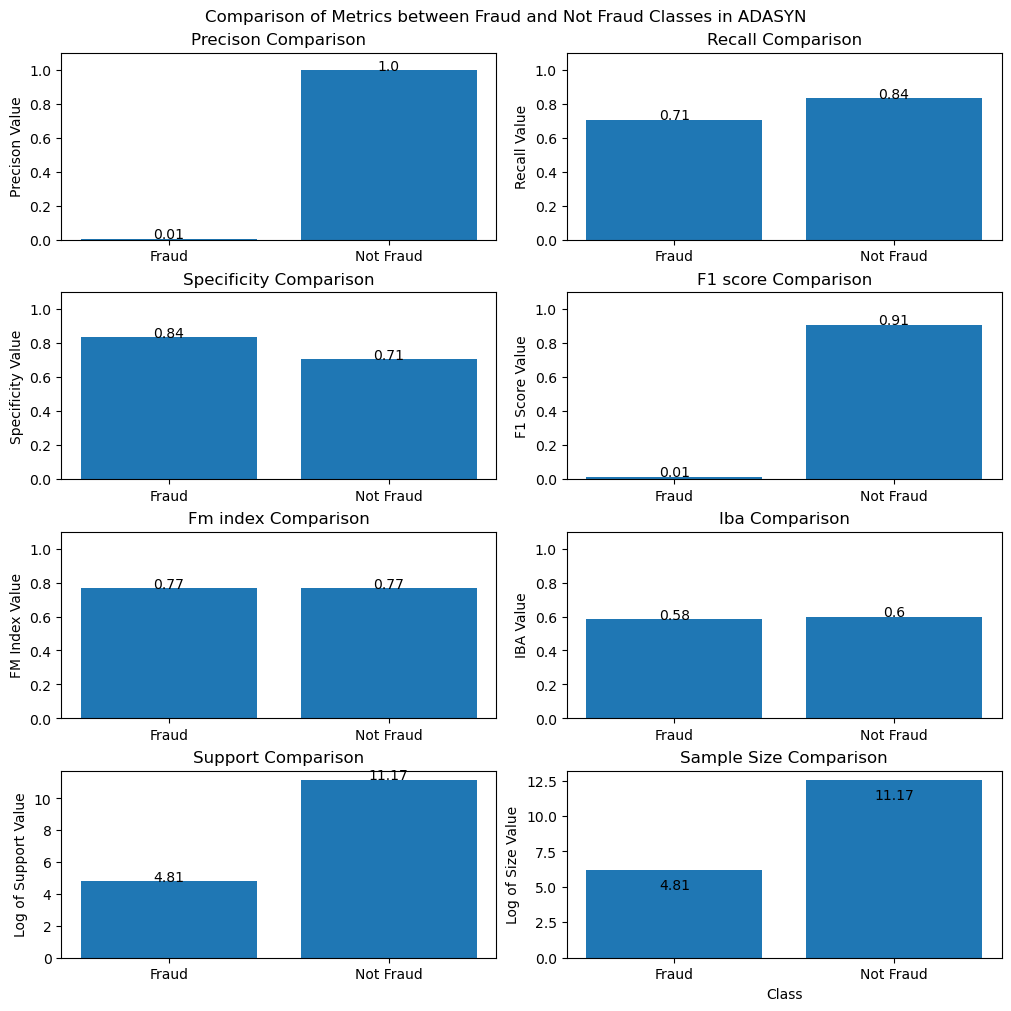

In [156]:
adasyn = ADASYN()
samplers.append("ADASYN")
classifiers.append(pipeline(data, name="ADASYN", sampler=adasyn))

#### Borderline SMOTE

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


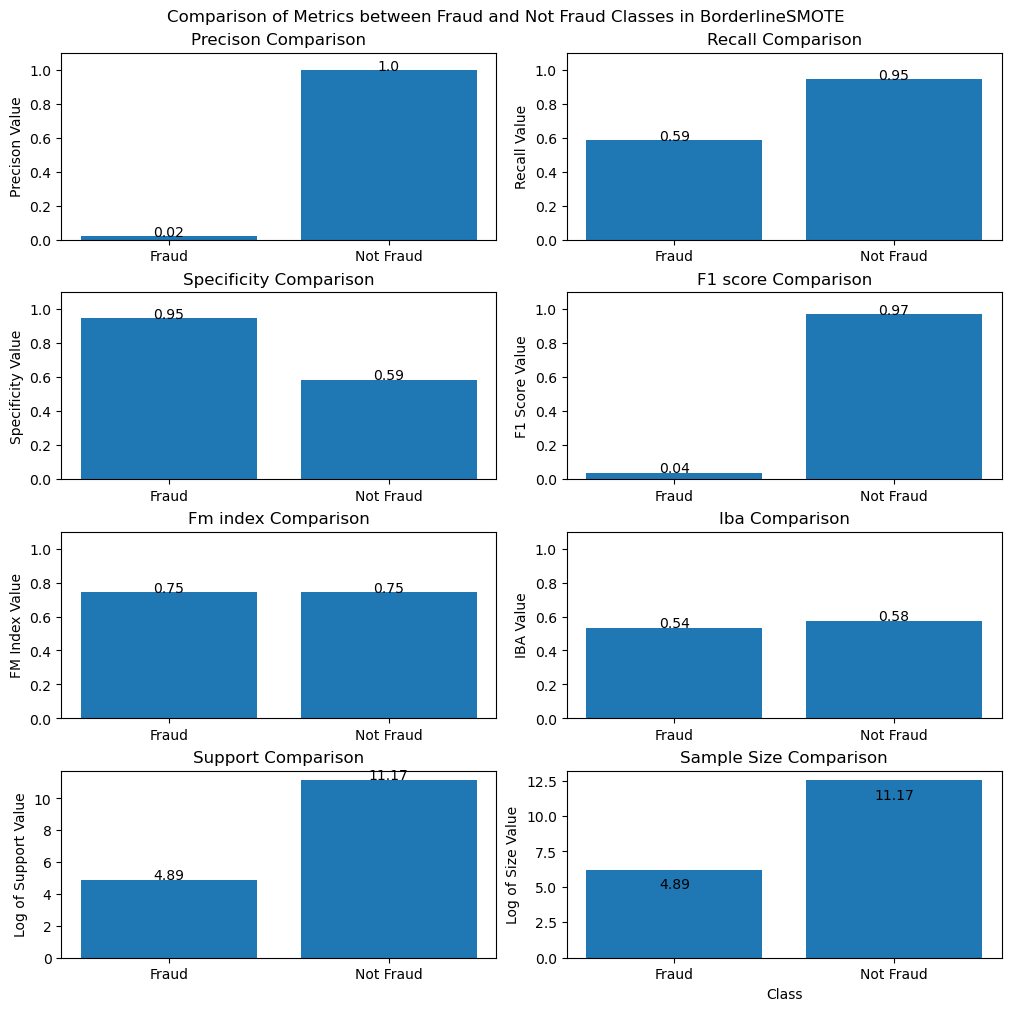

In [157]:
bsmote = BorderlineSMOTE()
samplers.append("BorderlineSMOTE")
classifiers.append(pipeline(data, name="BorderlineSMOTE", sampler=bsmote))

### Undersampling

We can choose to remove certain data points from the majority class. There are different ways of doing the same:

#### Random Under-sampling

Here we remove data points randomly from the dataset. The problem is we can potentially lose vital information about the data

In [158]:
new_neg_class = neg_class.sample(n=pos_class_count, replace=False)
data5 = pd.concat([new_neg_class, pos_class])
# data5.to_csv("data/random_undersample.csv", index=False)

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


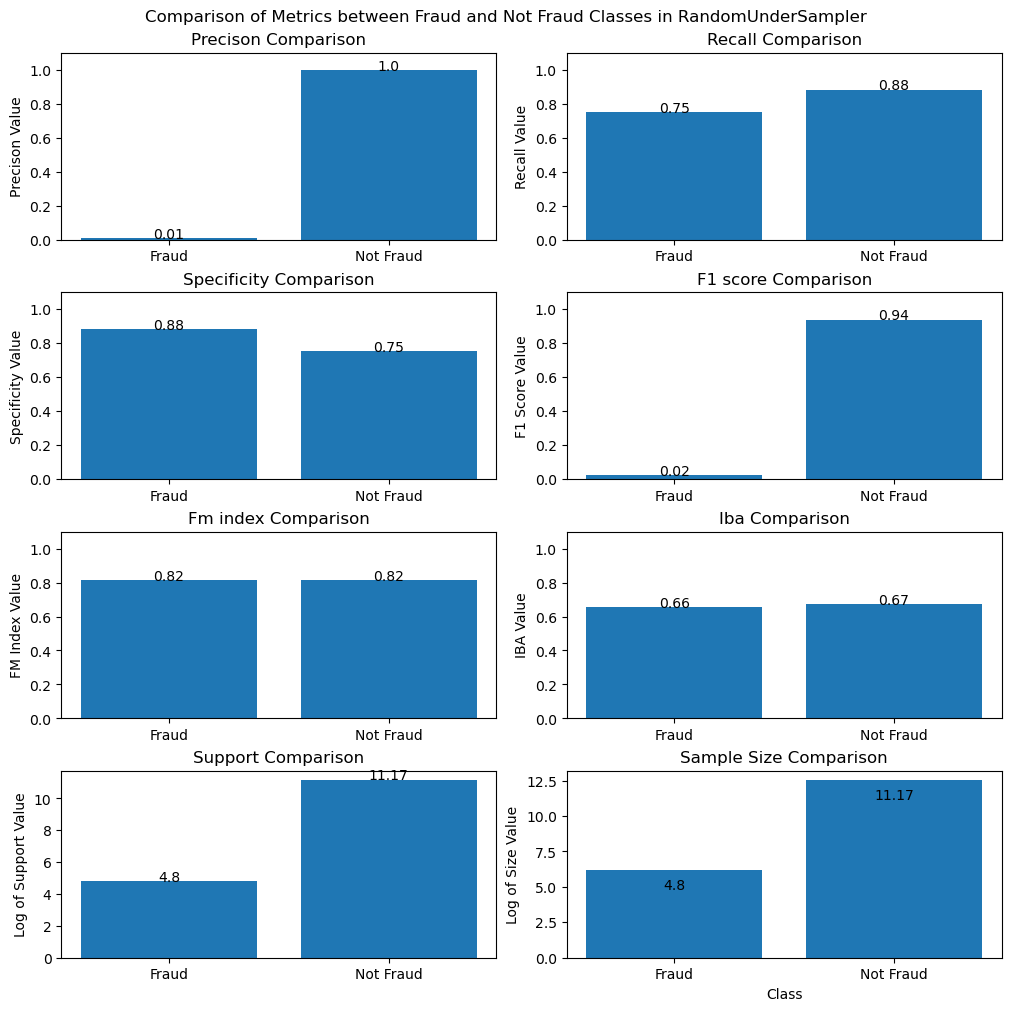

In [159]:
rus = RandomUnderSampler(random_state=42, replacement=True)# fit predictor and target variable
samplers.append("RandomUnderSampler")
classifiers.append(pipeline(data, name="RandomUnderSampler", sampler=rus))

#### Cluster Centroids

/tmp/ipykernel_7255/4160712559.py:67: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


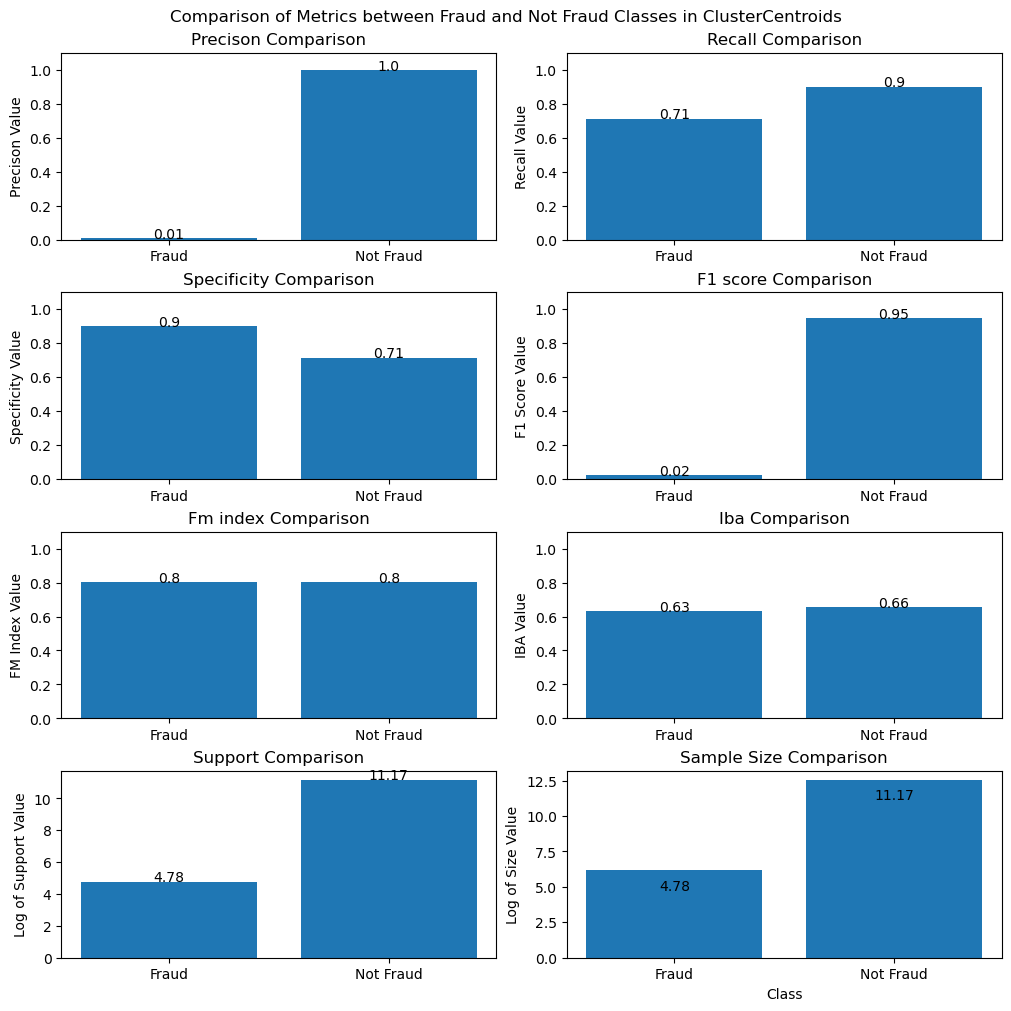

In [160]:
cc = ClusterCentroids(sampling_strategy="majority",
    estimator=MiniBatchKMeans(n_clusters=8)
)
samplers.append("ClusterCentroids")
classifiers.append(pipeline(data, "ClusterCentroids", cc))

#### Tomek links

Tomek-links are the pairs of points, each from a different class, which form the border between two clusters. What we can do is find all tomek-links between the two classes and remove the majority point from the pair, thereby decreasing the size of the majority class as well as increasing the classifiability between the two classes by increasing the distance between them.

## Use Better Balanced Metrics

In [ ]:
show_decision_functions(data)

In cases where we do not wish to modify the existing data, we can use or establish better methods of evaluating a model's performance where we consider more than just the predicted positive points. We want to use those tests which are mostly independent from the data distribution and rather looks into the test's discriminative power.

Let us look at why some of the popular metrics are not ideal for our setting:

#### Precision


#### Accuracy


#### F1


#### AUC-ROC



Let us look at some alternate metrics instead:

#### Balanced Accuracy

#### Matthew's Correlation Coefficent

#### AUC-PRC

Use AUCPRC or MCC or balanced accuracy instead of F1, Precision and Recall

## Test on the Model

In [ ]:
def build_model(data):
    x, y = data.drop(columns=['Class']), data['Class']
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=25)
    logreg = LogisticRegression(solver='lbfgs')
    logreg.fit(X_train, y_train)
    y_pred = logreg.predict(X_test)

    eval_metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balan
    }
    return logreg, eval_metrics

In [ ]:
models, total_eval_metrics = [], []
for d in range(len(datasets)):
    print(f"Dataset no {d+1}")
    print("-" * 50)
    data = datasets[d]
    model, em = build_model(data)
    models.append(model)
    total_eval_metrics.append(em)

Dataset no 1
--------------------------------------------------


/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Dataset no 2
--------------------------------------------------


/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Dataset no 3
--------------------------------------------------


/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Dataset no 4
--------------------------------------------------


/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#log

Dataset no 5
--------------------------------------------------
Dataset no 6
--------------------------------------------------


/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
fig, axs = plt.subplot((5, 2), figsize=(20, 10))
i, j = 0, 0
metrics = list(total_eval_metrics[0].keys())

for k in range(len(metrics)):
    metric = [em[metrics[k]] for em in total_eval_metrics]

    axs[i, j].plot(metric)
    axs[i, j].set_title(f"{metrics[k]} across different sampling methods")
    axs[i, j].set_xlabel("Sampling Methods")
    axs[i, j].set_ylabel(f"{metrics[k]} value")
    axs[i, j].set_ylim(0.8, 1)
    
    j += 1
    if j == 2:
        i += 1
        j = 0
plt.show()

## Final Results